<a href="https://colab.research.google.com/github/zeer055-a11y/Poll/blob/main/Example_RL_PID_PPO_CartPole.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 강화학습을 활용한 Cart-pole PID 게인 자동 튜닝

이 노트북은 PPO가 제어입력을 직접 생성하지 않고, 내부 각도 PID 제어기의 게인 `Kp`, `Ki`, `Kd`를 조정하도록 구성되어 있습니다. 외부 위치 PD 루프가 목표 막대 각도를 만들고, curriculum 방식으로 외란 난이도를 높이며 학습한 뒤 고정 PID와 RL-PID의 성능을 비교합니다.

아래 셀을 위에서부터 순서대로 실행하세요.

## 0. 패키지 설치

실행에 필요한 Gymnasium과 Stable-Baselines3를 설치하고, 그래프에서 한글이 깨지지 않도록 나눔 글꼴을 설치합니다. Colab 런타임에서는 가장 먼저 이 셀을 실행합니다.

In [ ]:
# ============================================================
# 0. 패키지 설치
# ============================================================
!pip install -q "gymnasium>=0.29" "stable-baselines3>=2.3"

# 한글 폰트
!apt-get -qq update
!apt-get -qq install -y fonts-nanum



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 3.8 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-nanum.
(Reading database ... 122809 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


## 1. 라이브러리 불러오기 및 시드 설정

수치 계산, 데이터 처리, 시각화, 강화학습 환경 구성에 필요한 라이브러리를 불러옵니다. 난수 시드를 고정하여 가능한 범위에서 실험 재현성을 확보하고, Matplotlib의 한글 표시 설정도 적용합니다.

In [ ]:
# ============================================================
# 1. Import
# ============================================================
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from dataclasses import dataclass
from typing import Optional

import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env

import torch

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import (
    BaseCallback,
    EvalCallback,
    CallbackList,
)

plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)



Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Cart-pole 동역학

Cart-pole의 물리 파라미터와 상태 미분식을 정의하고, 4차 Runge–Kutta 방법으로 상태를 적분합니다. 마지막의 간단한 단언문은 힘과 각가속도의 부호 관계가 의도한 동역학과 일치하는지 확인합니다.

In [ ]:
# ============================================================
# 2. Cart-pole 동역학
# ============================================================
@dataclass
class CartPoleParams:
    M: float = 1.0
    m: float = 0.1
    l: float = 0.5
    g: float = 9.8
    dt: float = 0.02


def state_derivative(state, u, disturbance, p):
    x, x_dot, theta, theta_dot = state

    total_force = u + disturbance
    sin_t = np.sin(theta)
    cos_t = np.cos(theta)
    total_mass = p.M + p.m

    denominator = p.l * (
        4.0 / 3.0
        - p.m * cos_t**2 / total_mass
    )

    theta_ddot = (
        p.g * sin_t
        - cos_t
        * (
            total_force
            + p.m * p.l * theta_dot**2 * sin_t
        )
        / total_mass
    ) / denominator

    x_ddot = (
        total_force
        + p.m
        * p.l
        * (
            theta_dot**2 * sin_t
            - theta_ddot * cos_t
        )
    ) / total_mass

    return np.array(
        [x_dot, x_ddot, theta_dot, theta_ddot],
        dtype=np.float64,
    )


def rk4_step(state, u, disturbance, p):
    dt = p.dt

    k1 = state_derivative(state, u, disturbance, p)
    k2 = state_derivative(
        state + 0.5 * dt * k1,
        u,
        disturbance,
        p,
    )
    k3 = state_derivative(
        state + 0.5 * dt * k2,
        u,
        disturbance,
        p,
    )
    k4 = state_derivative(
        state + dt * k3,
        u,
        disturbance,
        p,
    )

    next_state = state + (
        dt / 6.0
    ) * (k1 + 2 * k2 + 2 * k3 + k4)

    if not np.all(np.isfinite(next_state)):
        raise FloatingPointError("상태에 NaN 또는 Inf 발생")

    return next_state


# 부호 검증
test_state = np.array([
    0.0,
    0.0,
    np.deg2rad(2.0),
    0.0,
])

d0 = state_derivative(
    test_state,
    u=0.0,
    disturbance=0.0,
    p=CartPoleParams(),
)

d1 = state_derivative(
    test_state,
    u=1.0,
    disturbance=0.0,
    p=CartPoleParams(),
)

assert d0[3] > 0
assert d1[3] < d0[3]

print("동역학 부호 검증 통과")



동역학 부호 검증 통과


## 3. 내부 각도 PID 제어기

막대 각도를 안정화하는 내부 PID 제어기를 정의합니다. 적분 포화, 미분항 저역통과 필터, 제어입력 포화 및 clamping 방식의 anti-windup이 포함됩니다.

In [ ]:
# ============================================================
# 3. 내부 각도 PID
# ============================================================
@dataclass
class PIDConfig:
    dt: float = 0.02
    u_limit: float = 15.0
    integral_limit: float = 3.0
    derivative_alpha: float = 0.3


class AnglePID:
    def __init__(self, cfg):
        self.cfg = cfg
        self.reset()

    def reset(self):
        self.integral = 0.0
        self.prev_error = 0.0
        self.filtered_derivative = 0.0
        self.has_prev_error = False

    def compute(self, kp, ki, kd, error):
        dt = self.cfg.dt

        # 적분
        integral_candidate = self.integral + error * dt
        integral_candidate = np.clip(
            integral_candidate,
            -self.cfg.integral_limit,
            self.cfg.integral_limit,
        )

        # 미분
        if self.has_prev_error:
            raw_derivative = (
                error - self.prev_error
            ) / dt
        else:
            raw_derivative = 0.0

        alpha = self.cfg.derivative_alpha

        self.filtered_derivative = (
            alpha * raw_derivative
            + (1.0 - alpha)
            * self.filtered_derivative
        )

        u_unsat = (
            kp * error
            + ki * integral_candidate
            + kd * self.filtered_derivative
        )

        u = float(np.clip(
            u_unsat,
            -self.cfg.u_limit,
            self.cfg.u_limit,
        ))

        # Clamping anti-windup
        if abs(u_unsat) < self.cfg.u_limit:
            self.integral = float(integral_candidate)

        self.prev_error = float(error)
        self.has_prev_error = True

        return u




## 4. 외부 위치 PD 제어기

카트의 위치와 속도 오차로부터 목표 막대 각도 `theta_ref`를 생성하는 외부 PD 루프를 정의합니다. 생성된 목표 각도는 설정된 최대 범위 안으로 제한됩니다.

In [ ]:
# ============================================================
# 4. 외부 위치 PD
# ============================================================
@dataclass
class OuterPositionPD:
    kpx: float = 0.1
    kdx: float = 0.1
    theta_ref_max: float = np.deg2rad(10.0)

    def compute(self, x, x_dot, x_ref=0.0):
        theta_ref = (
            self.kpx * (x_ref - x)
            - self.kdx * x_dot
        )

        return float(np.clip(
            theta_ref,
            -self.theta_ref_max,
            self.theta_ref_max,
        ))




## 5. 환경·게인·보상 설정

물리 시뮬레이션 간격, 에피소드 길이, 상태 한계, 기준 PID 게인과 PPO가 조정할 수 있는 게인 범위를 설정합니다. PPO 행동을 실제 PID 게인으로 변환하는 함수, 관측 벡터 구성 함수, 물리 스텝별 보상 함수도 함께 정의합니다.

In [ ]:
# ============================================================
# 5. 환경 및 게인 설정
# ============================================================
PHYS_DT = 0.02
GAIN_UPDATE_EVERY = 5
EPISODE_LENGTH = 8.0

MAX_PHYS_STEPS = int(
    EPISODE_LENGTH / PHYS_DT
)

MAX_RL_STEPS = (
    MAX_PHYS_STEPS // GAIN_UPDATE_EVERY
)

X_LIMIT = 2.4
THETA_LIMIT = np.deg2rad(25.0)

X_DOT_SCALE = 3.0
THETA_DOT_SCALE = 5.0
DIST_SCALE = 6.0

# 안정한 기준 게인
NOMINAL_GAINS = np.array([
    20.0,
    0.0,
    4.0,
])

# PPO가 조정할 수 있는 범위
GAIN_SPAN = np.array([
    5.0,
    0.4,
    1.0,
])

GAIN_MIN = np.array([
    15.0,
    0.0,
    3.0,
])

GAIN_MAX = np.array([
    25.0,
    0.4,
    5.0,
])

GAIN_SMOOTHING = 0.15

# Reward 스케일
R_THETA = np.deg2rad(10.0)
R_X = 1.0
R_THETA_DOT = 3.0
R_X_DOT = 2.0

W_THETA = 3.0
W_X = 1.0
W_THETA_DOT = 0.15
W_X_DOT = 0.08
W_U = 0.02
W_DU = 0.01
W_GAIN_RATE = 0.01

TERMINATION_PENALTY = 10.0
SUCCESS_BONUS = 2.0


def action_to_gains(current_gains, action):
    action = np.clip(
        np.asarray(action, dtype=np.float64),
        -1.0,
        1.0,
    )

    target_gains = (
        NOMINAL_GAINS
        + action * GAIN_SPAN
    )

    target_gains = np.clip(
        target_gains,
        GAIN_MIN,
        GAIN_MAX,
    )

    new_gains = current_gains + (
        GAIN_SMOOTHING
        * (target_gains - current_gains)
    )

    normalized_rate = (
        new_gains - current_gains
    ) / GAIN_SPAN

    return new_gains, normalized_rate


def build_observation(
    x,
    x_dot,
    e_theta,
    theta_dot,
    integral,
    gains,
    prev_u,
    disturbance,
    u_limit,
):
    normalized_gains = (
        gains - NOMINAL_GAINS
    ) / GAIN_SPAN

    obs = np.array([
        x / X_LIMIT,
        x_dot / X_DOT_SCALE,
        e_theta / THETA_LIMIT,
        theta_dot / THETA_DOT_SCALE,
        integral / 3.0,
        normalized_gains[0],
        normalized_gains[1],
        normalized_gains[2],
        prev_u / u_limit,
        disturbance / DIST_SCALE,
    ], dtype=np.float32)

    return np.clip(obs, -5.0, 5.0)


def physics_reward(
    x,
    x_dot,
    e_theta,
    theta_dot,
    u,
    prev_u,
    u_limit,
):
    cost = (
        W_THETA
        * (e_theta / R_THETA) ** 2

        + W_X
        * (x / R_X) ** 2

        + W_THETA_DOT
        * (theta_dot / R_THETA_DOT) ** 2

        + W_X_DOT
        * (x_dot / R_X_DOT) ** 2

        + W_U
        * (u / u_limit) ** 2

        + W_DU
        * (
            (u - prev_u)
            / (2.0 * u_limit)
        ) ** 2
    )

    # exp(-cost)와 달리 상태가 나빠져도
    # 학습 신호가 완전히 0으로 사라지지 않음
    return float(np.clip(
        1.0 - cost,
        -5.0,
        1.0,
    ))




## 6. Curriculum 외란 생성기

학습 난이도에 따라 외란의 크기와 특성이 달라지는 생성기를 정의합니다. 에피소드마다 무외란, 펄스, 정현파, 랜덤 외란 중 하나를 선택하고 현재 시각의 외란 값을 계산합니다.

In [ ]:
# ============================================================
# 6. Curriculum 외란 생성기
# ============================================================
def sample_disturbance_config(
    rng,
    difficulty,
    episode_length,
):
    """
    difficulty:
        0 = 약한 외란
        1 = 최대 학습 외란
    """

    difficulty = float(np.clip(
        difficulty,
        0.0,
        1.0,
    ))

    kind = rng.choice(
        ["none", "pulse", "sine", "random"],
        p=[0.15, 0.50, 0.25, 0.10],
    )

    config = {"kind": kind}

    if kind == "pulse":
        magnitude_max = (
            0.5 + 3.5 * difficulty
        )

        config["magnitude"] = rng.uniform(
            0.3,
            magnitude_max,
        ) * rng.choice([-1.0, 1.0])

        config["start_time"] = rng.uniform(
            1.0,
            3.0,
        )

        config["duration"] = rng.uniform(
            0.3,
            1.2,
        )

    elif kind == "sine":
        config["amplitude"] = rng.uniform(
            0.2,
            0.5 + 2.0 * difficulty,
        )

        config["frequency"] = rng.uniform(
            0.2,
            0.5 + difficulty,
        )

        config["start_time"] = rng.uniform(
            1.0,
            2.0,
        )

        config["duration"] = rng.uniform(
            1.0,
            3.0,
        )

        config["phase"] = rng.uniform(
            0.0,
            2.0 * np.pi,
        )

    elif kind == "random":
        config["amplitude"] = (
            0.2 + 1.0 * difficulty
        )

    return config


def disturbance_at(config, time, rng):
    kind = config["kind"]

    if kind == "none":
        return 0.0

    if kind == "pulse":
        start = config["start_time"]
        end = start + config["duration"]

        if start <= time < end:
            return config["magnitude"]

        return 0.0

    if kind == "sine":
        start = config["start_time"]
        end = start + config["duration"]

        if not start <= time < end:
            return 0.0

        tau = time - start

        return (
            config["amplitude"]
            * np.sin(
                2.0
                * np.pi
                * config["frequency"]
                * tau
                + config["phase"]
            )
        )

    if kind == "random":
        return float(rng.uniform(
            -config["amplitude"],
            config["amplitude"],
        ))

    raise ValueError(kind)




## 7. Gymnasium 강화학습 환경

PPO가 PID의 `Kp`, `Ki`, `Kd`를 조정할 수 있도록 Gymnasium 환경을 구성합니다. 한 번의 RL 스텝 동안 여러 물리 스텝을 실행하며, 종료 조건·보상·관측·게인 갱신을 처리합니다. 마지막에는 Gymnasium 환경 규격을 검사합니다.

In [ ]:
# ============================================================
# 7. Gymnasium 환경
# ============================================================
class RLPIDCartPoleEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, seed=None):
        super().__init__()

        self.params = CartPoleParams(dt=PHYS_DT)
        self.outer_pd = OuterPositionPD()

        self.pid_cfg = PIDConfig(
            dt=PHYS_DT,
            u_limit=15.0,
            integral_limit=3.0,
            derivative_alpha=0.3,
        )

        self.pid = AnglePID(self.pid_cfg)

        self.observation_space = spaces.Box(
            low=-5.0,
            high=5.0,
            shape=(10,),
            dtype=np.float32,
        )

        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(3,),
            dtype=np.float32,
        )

        self.rng = np.random.default_rng(seed)
        self.difficulty = 0.15

    def set_difficulty(self, difficulty):
        self.difficulty = float(np.clip(
            difficulty,
            0.0,
            1.0,
        ))

    def reset(
        self,
        *,
        seed=None,
        options=None,
    ):
        super().reset(seed=seed)

        if seed is not None:
            self.rng = np.random.default_rng(seed)

        self.state = np.array([
            self.rng.uniform(-0.15, 0.15),
            self.rng.uniform(-0.08, 0.08),
            self.rng.uniform(
                np.deg2rad(-4.0),
                np.deg2rad(4.0),
            ),
            self.rng.uniform(-0.08, 0.08),
        ], dtype=np.float64)

        self.gains = NOMINAL_GAINS.copy()

        self.pid.reset()

        self.prev_u = 0.0
        self.current_disturbance = 0.0
        self.time = 0.0
        self.phys_step = 0

        self.dist_config = (
            sample_disturbance_config(
                self.rng,
                self.difficulty,
                EPISODE_LENGTH,
            )
        )

        self.dist_rng = np.random.default_rng(
            int(self.rng.integers(
                0,
                1_000_000,
            ))
        )

        return self._get_obs(), {}

    def _get_obs(self):
        x, x_dot, theta, theta_dot = self.state

        theta_ref = self.outer_pd.compute(
            x,
            x_dot,
        )

        # 현재 동역학 부호에 맞춘 오차
        e_theta = theta - theta_ref

        return build_observation(
            x=x,
            x_dot=x_dot,
            e_theta=e_theta,
            theta_dot=theta_dot,
            integral=self.pid.integral,
            gains=self.gains,
            prev_u=self.prev_u,
            disturbance=self.current_disturbance,
            u_limit=self.pid_cfg.u_limit,
        )

    def step(self, action):
        old_gains = self.gains.copy()

        self.gains, gain_rate = (
            action_to_gains(
                self.gains,
                action,
            )
        )

        reward_sum = 0.0
        executed_steps = 0
        terminated = False

        for _ in range(GAIN_UPDATE_EVERY):
            x, x_dot, theta, theta_dot = (
                self.state
            )

            theta_ref = self.outer_pd.compute(
                x,
                x_dot,
            )

            e_theta = theta - theta_ref

            u = self.pid.compute(
                kp=self.gains[0],
                ki=self.gains[1],
                kd=self.gains[2],
                error=e_theta,
            )

            self.current_disturbance = (
                disturbance_at(
                    self.dist_config,
                    self.time,
                    self.dist_rng,
                )
            )

            try:
                self.state = rk4_step(
                    self.state,
                    u,
                    self.current_disturbance,
                    self.params,
                )
            except FloatingPointError:
                terminated = True
                break

            self.time += PHYS_DT
            self.phys_step += 1
            executed_steps += 1

            (
                x_new,
                x_dot_new,
                theta_new,
                theta_dot_new,
            ) = self.state

            theta_ref_new = (
                self.outer_pd.compute(
                    x_new,
                    x_dot_new,
                )
            )

            e_theta_new = (
                theta_new - theta_ref_new
            )

            reward_sum += physics_reward(
                x=x_new,
                x_dot=x_dot_new,
                e_theta=e_theta_new,
                theta_dot=theta_dot_new,
                u=u,
                prev_u=self.prev_u,
                u_limit=self.pid_cfg.u_limit,
            )

            self.prev_u = u

            if (
                abs(x_new) > X_LIMIT
                or abs(theta_new) > THETA_LIMIT
            ):
                terminated = True
                break

        reward = (
            reward_sum
            / max(executed_steps, 1)
        )

        reward -= (
            W_GAIN_RATE
            * np.sum(gain_rate**2)
        )

        if terminated:
            reward -= TERMINATION_PENALTY

        truncated = (
            not terminated
            and self.phys_step
            >= MAX_PHYS_STEPS
        )

        if truncated:
            reward += SUCCESS_BONUS

        info = {
            "gains": self.gains.copy(),
            "is_success": bool(truncated),
            "difficulty": self.difficulty,
        }

        return (
            self._get_obs(),
            float(reward),
            terminated,
            truncated,
            info,
        )


test_env = RLPIDCartPoleEnv(seed=SEED)
check_env(test_env, skip_render_check=True)

print("Gymnasium 환경 검증 통과")



Gymnasium 환경 검증 통과


## 8. Curriculum callback

학습 진행률이 높아질수록 외란 난이도를 `0.15`에서 `1.0`까지 점진적으로 증가시키는 콜백을 정의합니다. 벡터화된 모든 학습 환경에 동일한 난이도를 전달합니다.

In [ ]:
# ============================================================
# 8. Curriculum callback
# ============================================================
class CurriculumCallback(BaseCallback):
    def __init__(self, total_timesteps):
        super().__init__()
        self.total_timesteps_target = (
            total_timesteps
        )

    def _on_step(self):
        progress = min(
            self.num_timesteps
            / self.total_timesteps_target,
            1.0,
        )

        # 처음부터 외란 0으로 시작하지 않고
        # 0.15 → 1.0으로 점진적으로 증가
        difficulty = 0.15 + 0.85 * progress

        self.training_env.env_method(
            "set_difficulty",
            difficulty,
        )

        return True




## 9. PPO 학습

병렬 학습 환경과 별도 평가 환경을 만들고 PPO 모델 및 콜백을 설정합니다. 학습 중 최고 성능 모델을 저장하며, 학습 완료 후 최고 모델이 있으면 이를 불러오고 그렇지 않으면 최종 모델을 사용합니다.

In [ ]:
# ============================================================
# 9. PPO 학습
# ============================================================
SMOKE_TEST = False
N_ENVS = 4

TOTAL_TIMESTEPS = (
    4_096
    if SMOKE_TEST
    else 150_000
)

train_env = make_vec_env(
    RLPIDCartPoleEnv,
    n_envs=N_ENVS,
    seed=SEED,
)

eval_env = Monitor(
    RLPIDCartPoleEnv(
        seed=SEED + 10_000,
    )
)

eval_env.unwrapped.set_difficulty(1.0)

BEST_MODEL_DIR = (
    "/content/rlpid_best"
    if os.path.isdir("/content")
    else "./rlpid_best"
)

os.makedirs(
    BEST_MODEL_DIR,
    exist_ok=True,
)


def learning_rate_schedule(
    progress_remaining,
):
    return 3e-4 * progress_remaining


model = PPO(
    policy="MlpPolicy",
    env=train_env,

    learning_rate=learning_rate_schedule,

    n_steps=512,
    batch_size=256,
    n_epochs=10,

    gamma=0.995,
    gae_lambda=0.95,

    clip_range=0.2,

    # 불필요한 탐색을 계속 장려하지 않음
    ent_coef=0.0,

    vf_coef=0.5,
    max_grad_norm=0.5,

    policy_kwargs=dict(
        net_arch=dict(
            pi=[128, 128],
            vf=[128, 128],
        ),
        activation_fn=torch.nn.Tanh,

        # 기존 std=1보다 훨씬 작은 초기 탐색
        log_std_init=-1.5,
    ),

    seed=SEED,
    verbose=1,
    device="cpu",
)

curriculum_callback = CurriculumCallback(
    TOTAL_TIMESTEPS
)

eval_callback = EvalCallback(
    eval_env,

    best_model_save_path=BEST_MODEL_DIR,
    log_path=BEST_MODEL_DIR,

    eval_freq=max(
        10_000 // N_ENVS,
        1,
    ),

    # 기존 5회보다 신뢰도 향상
    n_eval_episodes=20,

    deterministic=True,
    verbose=1,
)

callbacks = CallbackList([
    curriculum_callback,
    eval_callback,
])

model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=callbacks,
    progress_bar=False,
)

FINAL_MODEL_PATH = (
    "/content/rlpid_final"
    if os.path.isdir("/content")
    else "./rlpid_final"
)

model.save(FINAL_MODEL_PATH)

best_model_path = os.path.join(
    BEST_MODEL_DIR,
    "best_model.zip",
)

if os.path.exists(best_model_path):
    trained_model = PPO.load(
        best_model_path,
        device="cpu",
    )

    print(
        "가장 성능이 좋았던 모델을 불러왔습니다:",
        best_model_path,
    )
else:
    trained_model = PPO.load(
        FINAL_MODEL_PATH,
        device="cpu",
    )

    print("최종 모델을 불러왔습니다.")



Using cpu device
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 80       |
|    ep_rew_mean     | 73.7     |
|    success_rate    | 1        |
| time/              |          |
|    fps             | 340      |
|    iterations      | 1        |
|    time_elapsed    | 6        |
|    total_timesteps | 2048     |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------------
| rollout/                |           |
|    ep_len_mean          | 80        |
|    ep_rew_mean          | 73.2      |
|    success_rate         | 1         |
| time/                   |           |
|    fps                  | 400       |
|    iterations           | 2         |
|    time_elapsed         | 10        |
|    total_timesteps      | 4096      |
| train/                  |           |
|    approx_kl            | 0.0045184 |
|    clip_fraction        | 0.0146    |
|    clip_range           | 0.2       |
|    entropy_loss         | 0.237     |
|    explained_variance   | -0.000846 |
|    learning_rate        | 0.000296  |
|    loss                 | 74.9      |
|    n_updates            | 10        |
|    policy_gradient_loss | -0.00335  |
|    std                  | 0.224     |
|    value_loss           | 174       |
---------------------------------------
------------------------------------------
| rollout/                |          

## 10. 고정 PID와 RL-PID 평가

동일한 외란 조건과 시드에서 고정 PID와 RL-PID를 각각 실행합니다. 각도·위치 RMSE, 누적 보상, 성공 여부, 생존시간을 계산하고 여러 평가 시드의 평균과 표준편차를 표로 요약합니다.

In [ ]:
# ============================================================
# 10. 고정 PID와 RL-PID 평가
# ============================================================
def run_episode(
    seed,
    use_rl,
    difficulty=1.0,
):
    env = RLPIDCartPoleEnv(seed=seed)
    env.set_difficulty(difficulty)

    obs, info = env.reset(seed=seed)

    log = {
        "time": [],
        "x": [],
        "theta": [],
        "u": [],
        "disturbance": [],
        "kp": [],
        "ki": [],
        "kd": [],
        "reward": [],
    }

    total_reward = 0.0

    while True:
        if use_rl:
            action, _ = trained_model.predict(
                obs,
                deterministic=True,
            )
        else:
            # action=0이면 nominal gain 유지
            action = np.zeros(
                3,
                dtype=np.float32,
            )

        obs, reward, terminated, truncated, info = (
            env.step(action)
        )

        total_reward += reward

        log["time"].append(env.time)
        log["x"].append(env.state[0])
        log["theta"].append(env.state[2])
        log["u"].append(env.prev_u)
        log["disturbance"].append(
            env.current_disturbance
        )
        log["kp"].append(env.gains[0])
        log["ki"].append(env.gains[1])
        log["kd"].append(env.gains[2])
        log["reward"].append(reward)

        if terminated or truncated:
            break

    for key in log:
        log[key] = np.asarray(log[key])

    log["success"] = bool(truncated)
    log["total_reward"] = total_reward
    log["elapsed_time"] = env.time

    return log


def compute_metrics(log):
    """
    실패한 에피소드의 남은 시간을 한계 상태로
    padding하여 조기 종료가 RMSE를 낮추는 문제를 방지한다.
    """
    n_total = MAX_RL_STEPS
    n_valid = len(log["theta"])
    n_missing = n_total - n_valid

    theta_sq_sum = np.sum(
        log["theta"]**2
    )

    x_sq_sum = np.sum(
        log["x"]**2
    )

    if n_missing > 0:
        theta_sq_sum += (
            n_missing * THETA_LIMIT**2
        )

        x_sq_sum += (
            n_missing * X_LIMIT**2
        )

    theta_rmse = np.sqrt(
        theta_sq_sum / n_total
    )

    x_rmse = np.sqrt(
        x_sq_sum / n_total
    )

    return {
        "각도 RMSE [deg]": np.rad2deg(
            theta_rmse
        ),
        "위치 RMSE [m]": x_rmse,
        "누적 reward": log["total_reward"],
        "성공": float(log["success"]),
        "생존시간 [s]": log["elapsed_time"],
    }


def evaluate_seeds(
    seeds,
    difficulty,
):
    fixed_rows = []
    rl_rows = []

    example = None

    for i, seed in enumerate(seeds):
        fixed_log = run_episode(
            seed=seed,
            use_rl=False,
            difficulty=difficulty,
        )

        rl_log = run_episode(
            seed=seed,
            use_rl=True,
            difficulty=difficulty,
        )

        fixed_rows.append(
            compute_metrics(fixed_log)
        )

        rl_rows.append(
            compute_metrics(rl_log)
        )

        if i == 0:
            example = {
                "fixed": fixed_log,
                "rl": rl_log,
            }

    return (
        pd.DataFrame(fixed_rows),
        pd.DataFrame(rl_rows),
        example,
    )


N_EVAL_SEEDS = 30
EVAL_SEEDS = list(range(
    20_000,
    20_000 + N_EVAL_SEEDS,
))

df_fixed, df_rl, example = evaluate_seeds(
    seeds=EVAL_SEEDS,
    difficulty=1.0,
)


def summarize(df, name):
    return pd.Series({
        "각도 RMSE [deg]":
            f"{df['각도 RMSE [deg]'].mean():.3f}"
            f" ± {df['각도 RMSE [deg]'].std():.3f}",

        "위치 RMSE [m]":
            f"{df['위치 RMSE [m]'].mean():.3f}"
            f" ± {df['위치 RMSE [m]'].std():.3f}",

        "누적 reward":
            f"{df['누적 reward'].mean():.3f}"
            f" ± {df['누적 reward'].std():.3f}",

        "성공률":
            f"{100 * df['성공'].mean():.1f}%",

        "평균 생존시간 [s]":
            f"{df['생존시간 [s]'].mean():.3f}",
    }, name=name)


summary = pd.DataFrame([
    summarize(
        df_fixed,
        "고정 PID",
    ),
    summarize(
        df_rl,
        "RL-PID",
    ),
])

display(summary)



,각도 RMSE [deg],위치 RMSE [m],누적 reward,성공률,평균 생존시간 [s]
고정 PID,4.409 ± 5.923,0.305 ± 0.579,48.648 ± 38.283,90.0%,7.460
RL-PID,3.517 ± 4.045,0.194 ± 0.362,49.469 ± 39.166,96.7%,7.823


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# ============================================================
# 10-B. 추가 비교: RL 평균 게인을 고정한 PID
#
# 질문: RL의 이득이 "온라인 게인 적응" 때문인가,
#       아니면 "더 좋은 상수 게인 하나를 찾았기" 때문인가?
#
# 실행 조건: 섹션 9(PPO 학습)와 섹션 10(고정 PID vs RL-PID 평가)을
#            먼저 실행해야 합니다. (trained_model, df_fixed, df_rl,
#            EVAL_SEEDS, compute_metrics, summarize를 사용)
# ============================================================
from scipy.stats import wilcoxon


def run_episode_fixed(seed, gains, difficulty=1.0):
    """게인을 고정한 채 run_episode와 같은 방식으로 1 에피소드 실행."""
    gains = np.asarray(gains, dtype=np.float64)

    if np.any(gains < GAIN_MIN) or np.any(gains > GAIN_MAX):
        raise ValueError(f"게인이 허용 범위를 벗어났습니다: {gains}")

    env = RLPIDCartPoleEnv(seed=seed)
    env.set_difficulty(difficulty)
    env.reset(seed=seed)

    # 처음부터 지정 게인으로 시작하고,
    # 행동은 "그 게인을 그대로 유지"하는 값으로 고정한다.
    env.gains = gains.copy()
    hold_action = (gains - NOMINAL_GAINS) / GAIN_SPAN

    log = {
        key: []
        for key in [
            "time", "x", "theta", "u", "disturbance",
            "kp", "ki", "kd", "reward",
        ]
    }

    total_reward = 0.0

    while True:
        _, reward, terminated, truncated, _ = env.step(hold_action)

        total_reward += reward

        log["time"].append(env.time)
        log["x"].append(env.state[0])
        log["theta"].append(env.state[2])
        log["u"].append(env.prev_u)
        log["disturbance"].append(env.current_disturbance)
        log["kp"].append(env.gains[0])
        log["ki"].append(env.gains[1])
        log["kd"].append(env.gains[2])
        log["reward"].append(reward)

        if terminated or truncated:
            break

    for key in log:
        log[key] = np.asarray(log[key])

    log["success"] = bool(truncated)
    log["total_reward"] = total_reward
    log["elapsed_time"] = env.time

    # 게인이 정말 고정되어 있었는지 확인
    assert np.allclose(log["kp"], gains[0], atol=1e-6)
    assert np.allclose(log["ki"], gains[1], atol=1e-6)
    assert np.allclose(log["kd"], gains[2], atol=1e-6)

    return log


# ------------------------------------------------------------
# 1) 평가 시드 전체에서 RL이 실제로 쓴 게인의 평균 구하기
#    (에피소드별 시간 평균 -> 에피소드 평균)
# ------------------------------------------------------------
rl_logs = [
    run_episode(seed=seed, use_rl=True, difficulty=1.0)
    for seed in EVAL_SEEDS
]

episode_mean_gains = np.array([
    [log["kp"].mean(), log["ki"].mean(), log["kd"].mean()]
    for log in rl_logs
])

RL_MEAN_GAINS = episode_mean_gains.mean(axis=0)

# 직접 값을 지정하고 싶으면 아래 줄의 주석을 풀어 사용하세요.
# RL_MEAN_GAINS = np.array([18.8, 0.02, 4.07])

print("RL이 쓴 평균 게인 (Kp, Ki, Kd):", np.round(RL_MEAN_GAINS, 4))
print("에피소드 간 표준편차          :", np.round(episode_mean_gains.std(axis=0), 4))
print("기준 게인                     :", NOMINAL_GAINS)
print()

# ------------------------------------------------------------
# 2) 같은 시드·같은 외란에서 평균 게인 고정 PID 평가
# ------------------------------------------------------------
df_meanfixed = pd.DataFrame([
    compute_metrics(
        run_episode_fixed(seed, RL_MEAN_GAINS, difficulty=1.0)
    )
    for seed in EVAL_SEEDS
])

summary_3way = pd.DataFrame([
    summarize(df_fixed, "고정 PID (기준 게인)"),
    summarize(df_meanfixed, "고정 PID (RL 평균 게인)"),
    summarize(df_rl, "RL-PID"),
])

display(summary_3way)


# ------------------------------------------------------------
# 3) 시드별 짝지은 비교 (Wilcoxon signed-rank)
#    RMSE는 값이 작을수록, 생존시간은 클수록 좋음
# ------------------------------------------------------------
COMPARE_COLS = ["각도 RMSE [deg]", "위치 RMSE [m]", "생존시간 [s]"]


def paired_compare(df_a, name_a, df_b, name_b):
    rows = []

    for col in COMPARE_COLS:
        diff = df_a[col].to_numpy() - df_b[col].to_numpy()

        try:
            p_value = (
                np.nan
                if np.allclose(diff, 0)
                else wilcoxon(diff).pvalue
            )
        except ValueError:
            p_value = np.nan

        rows.append({
            "비교 (A − B)": f"{name_a} − {name_b}",
            "지표": col,
            "평균 차이": diff.mean(),
            "p-value": p_value,
        })

    return pd.DataFrame(rows)


paired_table = pd.concat([
    paired_compare(df_rl, "RL-PID", df_meanfixed, "평균게인 고정"),
    paired_compare(df_meanfixed, "평균게인 고정", df_fixed, "기준게인 고정"),
    paired_compare(df_rl, "RL-PID", df_fixed, "기준게인 고정"),
], ignore_index=True)

display(paired_table.round(4))

RL이 쓴 평균 게인 (Kp, Ki, Kd): [18.9722  0.0289  4.0599]
에피소드 간 표준편차          : [0.2339 0.0068 0.0251]
기준 게인                     : [20.  0.  4.]



,각도 RMSE [deg],위치 RMSE [m],누적 reward,성공률,평균 생존시간 [s]
고정 PID (기준 게인),4.409 ± 5.923,0.305 ± 0.579,48.648 ± 38.283,90.0%,7.460
고정 PID (RL 평균 게인),3.895 ± 5.083,0.250 ± 0.480,49.768 ± 39.375,93.3%,7.653
RL-PID,3.517 ± 4.045,0.194 ± 0.362,49.469 ± 39.166,96.7%,7.823


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,비교 (A − B),지표,평균 차이,p-value
0,RL-PID − 평균게인 고정,각도 RMSE [deg],-0.3786,0.1004
1,RL-PID − 평균게인 고정,위치 RMSE [m],-0.0556,0.9193
2,RL-PID − 평균게인 고정,생존시간 [s],0.1707,0.1797
3,평균게인 고정 − 기준게인 고정,각도 RMSE [deg],-0.5141,0.0145
4,평균게인 고정 − 기준게인 고정,위치 RMSE [m],-0.0553,0.0058
5,평균게인 고정 − 기준게인 고정,생존시간 [s],0.1927,0.2850
6,RL-PID − 기준게인 고정,각도 RMSE [deg],-0.8927,0.0767
7,RL-PID − 기준게인 고정,위치 RMSE [m],-0.1110,0.0405
8,RL-PID − 기준게인 고정,생존시간 [s],0.3633,0.2850


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 11. 대표 결과 그래프

대표 평가 에피소드에 대해 카트 위치, 막대 각도, 제어입력과 외란, RL이 조정한 PID 게인, 누적 보상을 차례로 시각화하여 두 제어기의 응답을 비교합니다.

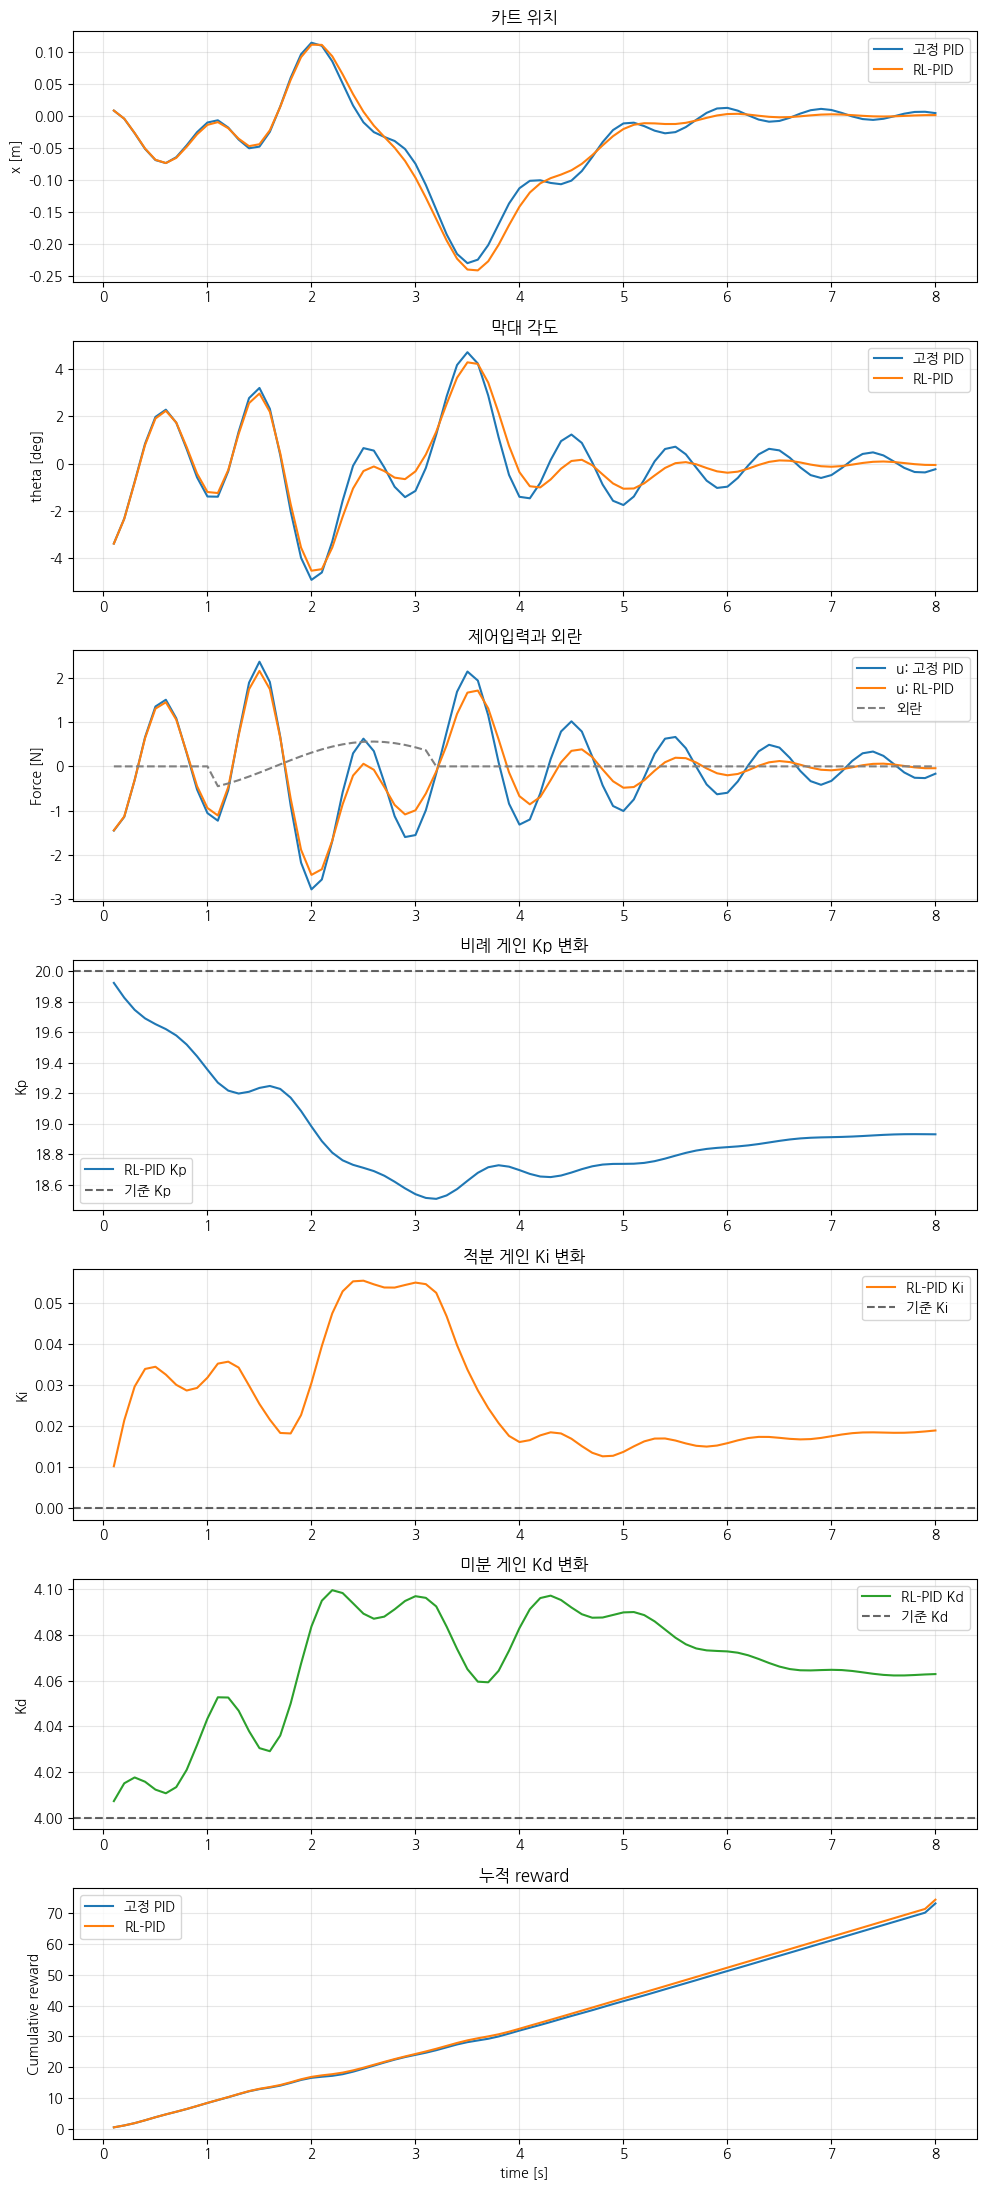

In [ ]:
# ============================================================
# 11. 대표 결과 그래프
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

# Colab 한글 폰트 설정
font_path = (
    "/usr/share/fonts/truetype/nanum/"
    "NanumGothic.ttf"
)

fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(
    fname=font_path
).get_name()

plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

fixed = example["fixed"]
rl = example["rl"]

fig, axes = plt.subplots(
    7,
    1,
    figsize=(10, 22),
)

# 1. 카트 위치
axes[0].plot(
    fixed["time"],
    fixed["x"],
    label="고정 PID",
)

axes[0].plot(
    rl["time"],
    rl["x"],
    label="RL-PID",
)

axes[0].set_ylabel("x [m]")
axes[0].set_title("카트 위치")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. 막대 각도
axes[1].plot(
    fixed["time"],
    np.rad2deg(fixed["theta"]),
    label="고정 PID",
)

axes[1].plot(
    rl["time"],
    np.rad2deg(rl["theta"]),
    label="RL-PID",
)

axes[1].set_ylabel("theta [deg]")
axes[1].set_title("막대 각도")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. 제어입력과 외란
axes[2].plot(
    fixed["time"],
    fixed["u"],
    label="u: 고정 PID",
)

axes[2].plot(
    rl["time"],
    rl["u"],
    label="u: RL-PID",
)

axes[2].plot(
    rl["time"],
    rl["disturbance"],
    "--",
    color="gray",
    label="외란",
)

axes[2].set_ylabel("Force [N]")
axes[2].set_title("제어입력과 외란")
axes[2].legend()
axes[2].grid(alpha=0.3)

# 4. 비례 게인 Kp
axes[3].plot(
    rl["time"],
    rl["kp"],
    color="tab:blue",
    label="RL-PID Kp",
)

axes[3].axhline(
    NOMINAL_GAINS[0],
    color="black",
    linestyle="--",
    alpha=0.6,
    label="기준 Kp",
)

axes[3].set_ylabel("Kp")
axes[3].set_title("비례 게인 Kp 변화")
axes[3].legend()
axes[3].grid(alpha=0.3)

# 5. 적분 게인 Ki
axes[4].plot(
    rl["time"],
    rl["ki"],
    color="tab:orange",
    label="RL-PID Ki",
)

axes[4].axhline(
    NOMINAL_GAINS[1],
    color="black",
    linestyle="--",
    alpha=0.6,
    label="기준 Ki",
)

axes[4].set_ylabel("Ki")
axes[4].set_title("적분 게인 Ki 변화")
axes[4].legend()
axes[4].grid(alpha=0.3)

# 6. 미분 게인 Kd
axes[5].plot(
    rl["time"],
    rl["kd"],
    color="tab:green",
    label="RL-PID Kd",
)

axes[5].axhline(
    NOMINAL_GAINS[2],
    color="black",
    linestyle="--",
    alpha=0.6,
    label="기준 Kd",
)

axes[5].set_ylabel("Kd")
axes[5].set_title("미분 게인 Kd 변화")
axes[5].legend()
axes[5].grid(alpha=0.3)

# 7. 누적 reward
axes[6].plot(
    fixed["time"],
    np.cumsum(fixed["reward"]),
    label="고정 PID",
)

axes[6].plot(
    rl["time"],
    np.cumsum(rl["reward"]),
    label="RL-PID",
)

axes[6].set_xlabel("time [s]")
axes[6].set_ylabel("Cumulative reward")
axes[6].set_title("누적 reward")
axes[6].legend()
axes[6].grid(alpha=0.3)

plt.tight_layout()
plt.show()